In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')
url = "https://raw.githubusercontent.com/microcrafted/DatasetOnlineshoppers/main/online_shoppers_intention.csv"

In [ ]:
#! ls -la drive/MyDrive/online_shoppers_intention.csv

In [ ]:
#df = pd.read_csv("drive/MyDrive/online_shoppers_intention.csv")
df = pd.read_csv(url)
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [ ]:
# 1. Revisar nulos y duplicados
print("Valores nulos por columna:\n", df.isnull().sum())
print("Filas duplicadas:", df.duplicated().sum())

# 2. Eliminar duplicados y reiniciar el índice (opcional según tu criterio)
df = df.drop_duplicates().reset_index(drop=True)
print("Filas después de limpiar:", len(df))

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [ ]:
# Quitamos las variables mas tecnicas esto para no distorcionar los centroides
X = df.drop(columns=["Revenue", "OperatingSystems", "Browser", "Region", "TrafficType"]).copy()

columnas_cat = ["Month", "VisitorType", "Weekend"]
columnas_num = [col for col in X.columns if col not in columnas_cat]

# Aseguramos tipo texto en las categóricas
for col in columnas_cat:
    X[col] = X[col].astype(str)

# Arreglamos las variables que podrian tener valores cercanos a 0 o son 0
columnas_sesgadas = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "PageValues"
]
for col in columnas_sesgadas:
    X[col] = np.log1p(X[col])

In [ ]:
# Codificación con get_dummies (0 y 1)
X_codificado = pd.get_dummies(X, drop_first=True)

In [ ]:
# Escalamos únicamente las columnas numéricas
X_escalado = X_codificado.copy()
scaler = StandardScaler()
X_escalado[columnas_num] = scaler.fit_transform(X_codificado[columnas_num])

In [ ]:
valores_k = range(2, 9)
inercia = []
silueta = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)

    inercia.append(modelo.inertia_)
    silueta.append(silhouette_score(X_escalado, etiquetas))

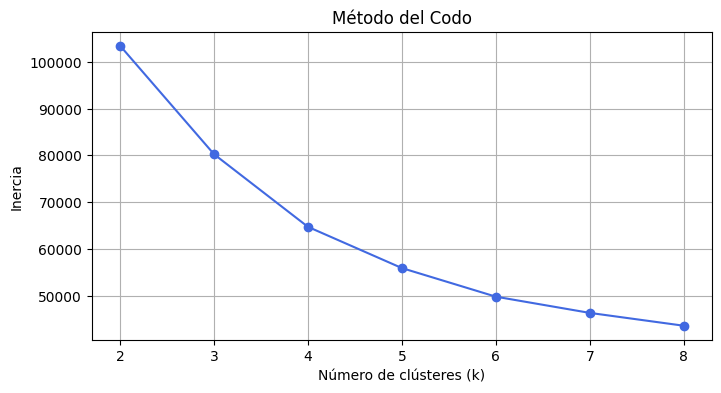

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercia, marker="o", color="royalblue")
plt.title("Método del Codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

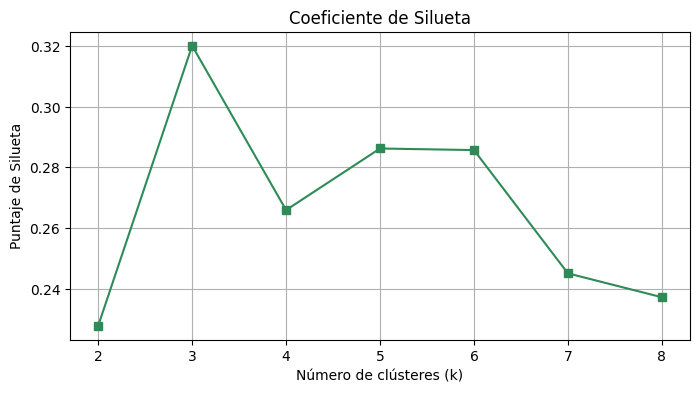

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(valores_k, silueta, marker="s", color="seagreen")
plt.title("Coeficiente de Silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Puntaje de Silueta")
plt.grid(True)
plt.show()

## Entrenamiento con el kmean optimo

In [ ]:
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_escalado)
df["Cluster"] = clusters

In [ ]:

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_escalado)
centroides = pca.transform(kmeans.cluster_centers_)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


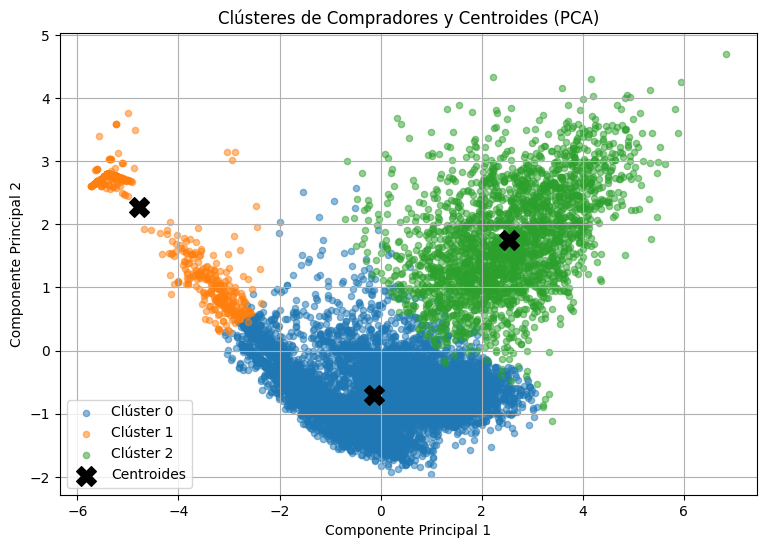

In [ ]:
# Graficamos clústeres y centroides juntos en la misma figura
plt.figure(figsize=(9, 6))

for i in range(k_optimo):
    plt.scatter(
        X_pca[clusters == i, 0],
        X_pca[clusters == i, 1],
        label=f"Clúster {i}",
        alpha=0.5,
        s=20,
    )

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    c="black",
    marker="X",
    s=200,
    label="Centroides",
    zorder=5,
)

plt.title("Clústeres de Compradores y Centroides (PCA)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Promedios por clúster para interpretar los resultados
resumen = df.groupby("Cluster").mean(numeric_only=True)
print(resumen.T)

Cluster                           0          1            2
Administrative             1.836507   0.030550     5.153414
Administrative_Duration   62.565079   0.186660   186.299586
Informational              0.038410   0.017312     2.525929
Informational_Duration     0.253304   0.070265   182.665219
ProductRelated            26.064534   2.244399    66.369058
ProductRelated_Duration  955.507519  31.145502  2622.550166
BounceRates                0.009795   0.171332     0.007296
ExitRates                  0.033173   0.184493     0.021708
PageValues                 5.830272   0.000000     8.618785
SpecialDay                 0.064578   0.092872     0.035782
OperatingSystems           2.122094   2.171079     2.111495
Browser                    2.390414   2.330957     2.238116
Region                     3.174452   3.075356     3.072169
TrafficType                4.066305   4.810591     3.767934
Weekend                    0.228692   0.172098     0.273552
Revenue                    0.147886   0.

In [ ]:
conteo = df["Cluster"].value_counts()
porcentaje = df["Cluster"].value_counts(normalize=True) * 100
print("--- Tamaño de los clústeres ---")
print(pd.DataFrame({"Sesiones": conteo, "Porcentaje (%) ": porcentaje.round(2)}))

--- Tamaño de los clústeres ---
         Sesiones  Porcentaje (%) 
Cluster                           
0            9034            73.27
2            2314            18.77
1             982             7.96
